# Task 1 — Feature extraction & analysis

## setup


In [ ]:
%%capture
%pip install numpy pandas scipy scikit-learn matplotlib seaborn statsmodels

In [ ]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer

train = pd.read_csv("train.csv")
valid = pd.read_csv("valid.csv")
test = pd.read_csv("test.csv")

base_cols = [
    "dialog_id", "speaker", "transcript",
    "da_tag", "start_time", "end_time"
]

end_pos = train.columns.get_loc("end_time")
liwc_cols = train.columns[end_pos + 1:].tolist()

counts = train["da_tag"].value_counts()

print("Train:", train.shape)
print("Validation:", valid.shape)
print("Test:", test.shape)
print(list(train.columns))
print( len(liwc_cols), " LIWC features are: ", liwc_cols)
print("Training labels:", train["da_tag"].nunique(), set(train["da_tag"]))


display(train.head(5))
display(train[base_cols].head(5))
display(counts)

Train: (74111, 79)
Validation: (19156, 79)
Test: (23540, 79)
['dialog_id', 'speaker', 'transcript', 'da_tag', 'start_time', 'end_time', 'function', 'pronoun', 'ppron', 'i', 'we', 'you', 'shehe', 'they', 'ipron', 'article', 'prep', 'auxverb', 'adverb', 'conj', 'negate', 'verb', 'adj', 'compare', 'interrog', 'number', 'quant', 'affect', 'posemo', 'negemo', 'anx', 'anger', 'sad', 'social', 'family', 'friend', 'female', 'male', 'cogproc', 'insight', 'cause', 'discrep', 'tentat', 'certain', 'differ', 'percept', 'see', 'hear', 'feel', 'bio', 'body', 'health', 'sexual', 'ingest', 'drives', 'affiliation', 'achieve', 'power', 'reward', 'risk', 'focuspast', 'focuspresent', 'focusfuture', 'relativ', 'motion', 'space', 'time', 'work', 'leisure', 'home', 'money', 'relig', 'death', 'informal', 'swear', 'netspeak', 'assent', 'nonflu', 'filler']
73  LIWC features are:  ['function', 'pronoun', 'ppron', 'i', 'we', 'you', 'shehe', 'they', 'ipron', 'article', 'prep', 'auxverb', 'adverb', 'conj', 'negate',

,dialog_id,speaker,transcript,da_tag,start_time,end_time,function,pronoun,ppron,i,...,home,money,relig,death,informal,swear,netspeak,assent,nonflu,filler
0,sw2005,B,SIL,x,0.00000,10.94882,0.000000,0.000000,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0
1,sw2005,A,SIL,x,10.93013,21.35084,0.000000,0.000000,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0
2,sw2005,B,well of course it's you know it's one of the l...,sv,10.94882,22.28000,0.642857,0.285714,0.190476,0.0,...,0.0,0.0,0.0,0.0,0.071429,0.0,0.0,0.0,0.071429,0.0
3,sw2005,A,yes,b,21.35084,22.08088,0.000000,0.000000,0.000000,0.0,...,0.0,0.0,0.0,0.0,1.000000,0.0,0.0,1.0,0.000000,0.0
4,sw2005,A,SIL,x,22.08088,44.96288,0.000000,0.000000,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0


,dialog_id,speaker,transcript,da_tag,start_time,end_time
0,sw2005,B,SIL,x,0.00000,10.94882
1,sw2005,A,SIL,x,10.93013,21.35084
2,sw2005,B,well of course it's you know it's one of the l...,sv,10.94882,22.28000
3,sw2005,A,yes,b,21.35084,22.08088
4,sw2005,A,SIL,x,22.08088,44.96288


da_tag
x     27024
sd    19149
b      9925
sv     7051
%      4101
aa     3136
qy     1253
ba     1063
ny      771
fc      638
Name: count, dtype: int64

## Text feature EDA

Number of SIL transcripts wrt each da_tag

In [59]:
sil = train["transcript"].fillna("").str.strip().str.upper().eq("SIL")

marker_summary = pd.crosstab(train["da_tag"],sil).reindex(columns=[False, True], fill_value=0)

marker_summary.columns = ["other_transcripts", "SIL_transcripts"]

display(marker_summary)

print("Examples labelled x without the SIL marker:")
display(train.loc[(train["da_tag"] == "x") & ~sil,["transcript", "da_tag"]].head(5))

,other_transcripts,SIL_transcripts
da_tag,,
%,4099,2
aa,3136,0
b,9919,6
ba,1063,0
fc,638,0
ny,771,0
qy,1253,0
sd,19147,2
sv,7051,0


Examples labelled x without the SIL marker:


,transcript,da_tag
297,<laughter>,x
355,<laughter>,x
376,<laughter>,x
381,<laughter>,x
414,<laughter>,x


word and char count

In [60]:
eda = train.copy()
eda["text"] = eda["transcript"].fillna("").str.lower().str.strip()

spoken_text = eda["text"].str.replace(
    r"<[^>]*>", " ", regex=True
)
spoken_text = spoken_text.mask(eda["text"].eq("sil"), "")

pattern = r"\b[a-z]+(?:['-][a-z]+)*\b"
tokens = spoken_text.str.findall(pattern)

eda["word_count"] = tokens.str.len()
eda["char_count"] = spoken_text.str.strip().str.len()

order = train["da_tag"].value_counts().index.tolist()

lengths = eda.groupby("da_tag").agg(
    examples=("word_count", "size"),
    mean_words=("word_count", "mean"),
    median_words=("word_count", "median"),
    mean_chars=("char_count", "mean")
).reindex(order)

display(lengths.round(2))

,examples,mean_words,median_words,mean_chars
da_tag,,,,
x,27024,0.01,0.0,0.03
sd,19149,10.49,9.0,50.32
b,9925,1.07,1.0,5.00
sv,7051,11.95,10.0,59.30
%,4101,2.40,2.0,9.11
aa,3136,1.71,1.0,7.60
qy,1253,8.11,7.0,38.59
ba,1063,2.67,2.0,12.35
ny,771,1.18,1.0,4.71


utterance count and duration

Number of utterances:


,Training,Validation
da_tag,,
x,27024,7174
sd,19149,5122
b,9925,2409
sv,7051,1765
%,4101,1033
aa,3136,664
qy,1253,342
ba,1063,320
ny,771,206


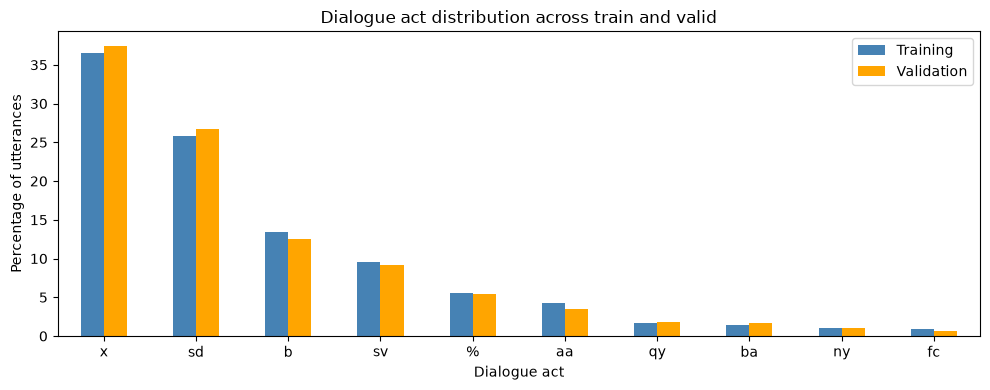

In [61]:
counts = pd.DataFrame()
counts["Training"] = train["da_tag"].value_counts()
counts["Validation"] = valid["da_tag"].value_counts()

percentages = pd.DataFrame()
percentages["Training"] = counts["Training"] / len(train) * 100
percentages["Validation"] = counts["Validation"] / len(valid) * 100

print("Number of utterances:")
display(counts)

ax = percentages.plot.bar(
    figsize=(10, 4),
    color=["steelblue", "orange"],
    rot=0
)

ax.set_title("Dialogue act distribution across train and valid")
ax.set_xlabel("Dialogue act")
ax.set_ylabel("Percentage of utterances")

plt.tight_layout()
plt.show()

In [62]:
train["duration"] = train["end_time"] - train["start_time"]
valid["duration"] = valid["end_time"] - valid["start_time"]

display(train.groupby("da_tag")["duration"].agg(["mean", "median", "std"]).round(2))

,mean,median,std
da_tag,,,
%,0.93,0.63,0.89
aa,0.72,0.57,0.65
b,0.63,0.48,0.82
ba,1.09,0.91,0.81
fc,1.10,0.74,1.03
ny,0.56,0.45,0.42
qy,2.26,1.80,1.71
sd,3.14,2.48,2.39
sv,3.63,2.77,3.04


repetitions

In [63]:
eda["has_repeat"] = tokens.map(
    lambda words: any(a == b for a, b in zip(words, words[1:]))
)

disfluency = (
    eda.groupby("da_tag")[
        [ "has_repeat"]
    ].mean()
    .reindex(order)
    .mul(100)
)

display(disfluency.round(2))

,has_repeat
da_tag,
x,0.00
sd,14.58
b,0.18
sv,18.22
%,6.51
aa,1.47
qy,9.02
ba,1.79
ny,0.13


top 5 LIWC features per class

In [64]:
excluded = ["dialog_id", "speaker", "transcript", "da_tag","start_time", "end_time", "word_count", "duration"]

categories = [col for col in train.columns if col not in excluded]
averages = train.groupby("da_tag")[categories].mean()

for label in averages.index:
    highest = averages.loc[label].nlargest(5)

    print(f"\nDialogue act: {label}")
    print(highest.round(3))


Dialogue act: %
function    0.671
conj        0.287
pronoun     0.239
informal    0.228
adverb      0.159
Name: %, dtype: float64

Dialogue act: aa
informal    0.495
assent      0.456
function    0.258
relativ     0.156
space       0.154
Name: aa, dtype: float64

Dialogue act: b
informal    0.860
assent      0.773
relativ     0.101
space       0.101
nonflu      0.085
Name: b, dtype: float64

Dialogue act: ba
function    0.350
affect      0.333
posemo      0.316
informal    0.222
pronoun     0.210
Name: ba, dtype: float64

Dialogue act: fc
function    0.334
affect      0.243
posemo      0.242
informal    0.226
social      0.203
Name: fc, dtype: float64

Dialogue act: ny
informal    0.980
assent      0.921
nonflu      0.060
function    0.020
adverb      0.012
Name: ny, dtype: float64

Dialogue act: qy
function        0.641
verb            0.274
pronoun         0.232
focuspresent    0.221
auxverb         0.190
Name: qy, dtype: float64

Dialogue act: sd
function        0.620
pronoun      

In [65]:
# stopwords and POS
from spacy.lang.en.stop_words import STOP_WORDS

def clean_spoken(text, remove_stopwords=False):
    text = text.strip().lower()

    if text == "sil":
        return ""

    text = re.sub(r"<[^>]*>", " ", text).strip()

    if remove_stopwords:
        words = re.findall(pattern, text)
        text = " ".join(
            word for word in words
            if word not in STOP_WORDS
        )

    return text

nlp = spacy.load( "en_core_web_sm", disable=["parser", "ner", "lemmatizer"])

pos_tags = ["NOUN", "PROPN", "VERB", "AUX", "ADJ", "ADV", "PRON", "INTJ"]

def pos_features(texts):
    rows = []
    cleaned = [clean_spoken(text) for text in texts]

    for doc in nlp.pipe(cleaned, batch_size=256):
        tags = [
            token.pos_ for token in doc
            if not token.is_punct
            and not token.is_space
            and token.pos_ != "SYM"
        ]

        counts = Counter(tags)
        total = max(len(tags), 1)

        rows.append({
            "pos_" + tag.lower(): counts[tag] / total
            for tag in pos_tags
        })
    return pd.DataFrame(rows)

In [66]:
inspection = train[["transcript", "da_tag"]].copy()
tokens = inspection["transcript"].fillna("").apply(clean_spoken).str.findall(pattern)

inspection["first_word"] = tokens.apply(
    lambda words: words[0] if words else ""
)
inspection["last_word"] = tokens.apply(
    lambda words: words[-1] if words else ""
)

for label, group in inspection.groupby("da_tag"):
    print(f"\nDialogue act: {label}")

    print("Common opening words:")
    print(group.loc[group["first_word"] != "", "first_word"]
          .value_counts(normalize=True).head(5).round(3))

    print("Common ending words:")
    print(group.loc[group["last_word"] != "", "last_word"]
          .value_counts(normalize=True).head(5).round(3))


Dialogue act: %
Common opening words:
first_word
and     0.165
so      0.122
but     0.101
i       0.091
yeah    0.055
Name: proportion, dtype: float64
Common ending words:
last_word
uh      0.127
so      0.084
yeah    0.062
i       0.052
and     0.042
Name: proportion, dtype: float64

Dialogue act: aa
Common opening words:
first_word
yeah      0.313
right     0.120
that's    0.103
oh        0.064
i         0.058
Name: proportion, dtype: float64
Common ending words:
last_word
yeah     0.340
right    0.189
yes      0.063
true     0.053
no       0.046
Name: proportion, dtype: float64

Dialogue act: b
Common opening words:
first_word
uh-huh    0.372
yeah      0.353
right     0.100
oh        0.069
okay      0.017
Name: proportion, dtype: float64
Common ending words:
last_word
uh-huh    0.377
yeah      0.376
right     0.102
oh        0.036
okay      0.020
Name: proportion, dtype: float64

Dialogue act: ba
Common opening words:
first_word
oh        0.359
that's    0.128
well      0.102
wow 

In [67]:
# positional features: first and last words

word_lists = [
    re.findall(pattern, clean_spoken(text))
    for text in train["transcript"].fillna("")
]

opening_counts = Counter(words[0] for words in word_lists if words)
ending_counts = Counter(words[-1] for words in word_lists if words)

opening_words = [word for word, count in opening_counts.most_common(20)]
ending_words = [word for word, count in ending_counts.most_common(10)]

print("Opening words:", opening_words)
print("Ending words:", ending_words)

Opening words: ['and', 'yeah', 'i', 'uh-huh', 'but', 'so', 'well', 'oh', 'right', 'uh', "that's", 'you', "it's", 'it', 'they', 'we', 'yes', 'the', 'um', "i'm"]
Ending words: ['yeah', 'uh-huh', 'right', 'uh', 'it', 'know', 'that', 'yes', 'so', 'and']


In [68]:
print(liwc_cols)

['function', 'pronoun', 'ppron', 'i', 'we', 'you', 'shehe', 'they', 'ipron', 'article', 'prep', 'auxverb', 'adverb', 'conj', 'negate', 'verb', 'adj', 'compare', 'interrog', 'number', 'quant', 'affect', 'posemo', 'negemo', 'anx', 'anger', 'sad', 'social', 'family', 'friend', 'female', 'male', 'cogproc', 'insight', 'cause', 'discrep', 'tentat', 'certain', 'differ', 'percept', 'see', 'hear', 'feel', 'bio', 'body', 'health', 'sexual', 'ingest', 'drives', 'affiliation', 'achieve', 'power', 'reward', 'risk', 'focuspast', 'focuspresent', 'focusfuture', 'relativ', 'motion', 'space', 'time', 'work', 'leisure', 'home', 'money', 'relig', 'death', 'informal', 'swear', 'netspeak', 'assent', 'nonflu', 'filler']


## Text features extraction

In [69]:
def custom_features(texts):
    rows = []

    for text in texts:
        raw = text.strip().lower()
        words = re.findall(pattern, clean_spoken(text))
        repeats = sum(a == b for a, b in zip(words, words[1:]))

        rows.append({
            "word_count": len(words),
            "log_word_count": np.log1p(len(words)),
            "char_count": len(" ".join(words)),
            "avg_word_length": (
                sum(len(w) for w in words) / len(words) if words else 0
            ),
            "unique_word_ratio": (
                len(set(words)) / len(words) if words else 0
            ),
            "has_laughter": int("<laughter>" in raw),
            "repeat_count": repeats,
            "ends_cut": int(raw.endswith("-")),
            "cut_count": len(re.findall(r"\b[a-z]+-(?=\s|$)", raw)),
            "is_sil": int(raw == "sil"),
            "has_laughter": int("<laughter>" in raw),
        })

    return pd.DataFrame(rows)

In [70]:
vec = TfidfVectorizer(
    token_pattern=pattern,
    ngram_range=(1, 2),
    max_features=200,
    min_df=20,
    sublinear_tf=True,
    dtype=np.float32
)

vec.fit(
    train["transcript"].fillna("").apply(clean_spoken)
)

tfidf_cols = [
    "tfidf_" + term
    for term in vec.get_feature_names_out()
]

In [ ]:
context_cols = [
    "word_count",
    "liwc_interrog",
    "liwc_assent",
    "ends_cut"
]

def context_features(df, base):
    previous_cols = ["previous_other_" + col for col in context_cols]
    following_cols = ["following_other_" + col for col in context_cols]

    context = pd.DataFrame(
        0.0,
        index=df.index,
        columns=previous_cols + following_cols
                 + ["has_previous_other", "has_following_other"]
    )

    for speaker in df["speaker"].unique():
        current = df["speaker"].eq(speaker)

        other_spoken = (
            df["speaker"].ne(speaker)
            & base["word_count"].gt(0)
        )

        source = base[context_cols].where(other_spoken)

        previous = source.groupby(df["dialog_id"]).ffill()
        following = source.groupby(df["dialog_id"]).bfill()

        context.loc[current, previous_cols] = (
            previous.loc[current].fillna(0).to_numpy()
        )

        context.loc[current, following_cols] = (
            following.loc[current].fillna(0).to_numpy()
        )

        context.loc[current, "has_previous_other"] = (
            previous.loc[current, "word_count"].notna().astype(int)
        )

        context.loc[current, "has_following_other"] = (
            following.loc[current, "word_count"].notna().astype(int)
        )

    context["previous_row_words"] = (
        base["word_count"].groupby(df["dialog_id"])
        .shift(1).fillna(0)
    )

    context["following_row_words"] = (
        base["word_count"].groupby(df["dialog_id"])
        .shift(-1).fillna(0)
    )

    return context

In [72]:
def extract_text_features(df):
    df = df.reset_index(drop=True)
    texts = df["transcript"].fillna("").tolist()

    words = [
        re.findall(pattern, clean_spoken(text))
        for text in texts
    ]

    custom = custom_features(texts)
    liwc = df[liwc_cols].add_prefix("liwc_")
    pos = pos_features(texts)

    base = pd.concat([custom, liwc], axis=1)

    boundaries = pd.DataFrame({
        **{
            "first_" + word: [
                int(bool(row) and row[0] == word)
                for row in words
            ]
            for word in opening_words
        },
        **{
            "last_" + word: [
                int(bool(row) and row[-1] == word)
                for row in words
            ]
            for word in ending_words
        }
    })

    dialogue = df.groupby("dialog_id")

    position = pd.DataFrame({
        "dialogue_position": (
            dialogue.cumcount()
            / (dialogue["dialog_id"].transform("size") - 1).clip(lower=1)
        ),
        "rows_from_end": dialogue.cumcount(ascending=False).clip(upper=20)
    })

    context = context_features(df, base)

    lexical = pd.DataFrame(
        vec.transform([
            clean_spoken(text) for text in texts
        ]).toarray(),
        columns=tfidf_cols
    )

    return pd.concat(
        [df[["dialog_id", "speaker","da_tag", "start_time", "end_time"]], base, pos, boundaries, position, context, 
         lexical],
        axis=1
    )

In [56]:
from pathlib import Path

Path("task1aa").mkdir(exist_ok=True)

text_features_train = extract_text_features(train)
text_features_valid = extract_text_features(valid)
text_features_test = extract_text_features(test)

for split, features in [
    ("train", text_features_train),
    ("valid", text_features_valid),
    ("test", text_features_test)
]:
    features.to_csv(
        f"task1aa/text_features_{split}.csv",
        index=False
    )
    print(split, features.shape)

train (74111, 340)
valid (19156, 340)
test (23540, 340)


## Speech features EDA & extraction

In [73]:
%%capture
%pip install -q praat-parselmouth tqdm

import pandas as pd
import numpy as np
import os
import parselmouth
from parselmouth.praat import call
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm

wav_dir = Path("./wav")

meta_cols = ["dialog_id", "speaker", "da_tag", "start_time", "end_time"]

In [74]:
def pitch_features(sound):
    pitch = call(sound, "To Pitch", 0.01, 75, 600)

    f0 = pitch.selected_array["frequency"]
    voiced = f0[f0 > 0]

    features = {
        "pitch_min": np.nan,
        "pitch_max": np.nan,
        "pitch_mean": np.nan,
        "pitch_std": np.nan,
        "voiced_fraction": np.mean(f0 > 0)
    }

    if len(voiced):
        features.update({
            "pitch_min": voiced.min(),
            "pitch_max": voiced.max(),
            "pitch_mean": voiced.mean(),
            "pitch_std": voiced.std()
        })

    return features

def intensity_features(sound):
    intensity = call(sound, "To Intensity", 100, 0.01, "yes")

    return {
        "intensity_min": call(
            intensity, "Get minimum", 0, 0, "Parabolic"
        ),
        "intensity_max": call(
            intensity, "Get maximum", 0, 0, "Parabolic"
        ),
        "intensity_mean": call(
            intensity, "Get mean", 0, 0, "energy"
        ),
        "intensity_std": call(
            intensity, "Get standard deviation", 0, 0
        )
    }

def voice_features(sound):
    pulses = call(
        sound, "To PointProcess (periodic, cc)", 75, 600
    )

    jitter = call(
        pulses, "Get jitter (local)",
        0, 0, 0.0001, 0.02, 1.3
    )

    shimmer = call(
        [sound, pulses], "Get shimmer (local)",
        0, 0, 0.0001, 0.02, 1.3, 1.6
    )

    harmonicity = call(
        sound, "To Harmonicity (cc)",
        0.01, 75, 0.1, 1.0
    )

    hnr = call(harmonicity, "Get mean", 0, 0)

    return {
        "jitter": jitter,
        "shimmer": shimmer,
        "hnr": hnr
    }

acoustic_cols = [
    "pitch_min", "pitch_max", "pitch_mean", "pitch_std",
    "voiced_fraction",
    "intensity_min", "intensity_max",
    "intensity_mean", "intensity_std",
    "jitter", "shimmer", "hnr"
]


def get_speech_features(sound):
    y = sound.values[0]

    features = {
        "duration": sound.get_total_duration(),
        "rms": np.sqrt(np.mean(y ** 2))
    }

    features.update({col: np.nan for col in acoustic_cols})

    if features["duration"] < 0.065:
        return features

    features.update(pitch_features(sound))
    features.update(intensity_features(sound))

    if features["voiced_fraction"] > 0:
        features.update(voice_features(sound))

    return features


In [75]:
def extract_speech_features(df):
    df = df.reset_index(drop=True)
    rows = []

    groups = df.groupby(["dialog_id", "speaker"], sort=False)

    for (dialog, speaker), group in tqdm(
        groups, total=groups.ngroups
    ):
        path = wav_dir / f"{dialog}_{speaker}.wav"
        sound = parselmouth.Sound(str(path))

        for i, row in group.iterrows():
            segment = sound.extract_part(
                from_time=row["start_time"],
                to_time=row["end_time"],
                preserve_times=False
            )

            features = get_speech_features(segment)
            features["row_id"] = i
            rows.append(features)

    features = (
        pd.DataFrame(rows)
        .set_index("row_id")
        .reindex(df.index)
        .reset_index(drop=True)
    )

    return pd.concat(
        [df[meta_cols], features],
        axis=1
    )

sample = (
    train.groupby("da_tag", group_keys=False)
    .sample(n=100, random_state=17)
    .reset_index(drop=True)
)

speech_sample = extract_speech_features(sample)

display(speech_sample.head())

100%|██████████| 473/473 [00:38<00:00, 12.38it/s]


,dialog_id,speaker,da_tag,start_time,end_time,duration,rms,pitch_min,pitch_max,pitch_mean,pitch_std,voiced_fraction,intensity_min,intensity_max,intensity_mean,intensity_std,jitter,shimmer,hnr
0,sw2061,A,%,36.066550,36.871330,0.804780,0.084420,77.473137,141.922515,124.820973,15.047304,0.857143,56.551179,78.377576,72.676631,5.210275,0.022225,0.050443,14.751118
1,sw2465,B,%,462.080000,462.761850,0.681850,0.005365,92.330373,200.369835,166.197733,26.013118,0.307692,20.146839,59.357737,48.853893,7.815770,0.035371,0.135067,-0.123780
2,sw4917,B,%,131.851490,132.171430,0.319940,0.011442,105.861165,118.773564,111.463534,3.979065,0.714286,40.094261,60.411070,55.974951,6.072095,0.013740,0.121504,7.286471
3,sw3676,A,%,207.974285,209.462649,1.488364,0.001439,82.517566,115.501197,91.315092,8.608530,0.172414,19.392406,49.220376,37.229127,9.314350,0.048380,0.264104,3.679719
4,sw3887,A,%,297.294730,297.760000,0.465270,0.044902,113.590069,131.884514,116.913206,4.503967,0.627907,31.131597,72.061918,66.988168,15.075643,0.015560,0.084926,15.894878


,duration,rms,pitch_mean,pitch_std,intensity_mean,voiced_fraction
da_tag,,,,,,
x,5.237,0.005,194.819,52.288,39.237,0.289
sd,3.088,0.036,159.643,34.623,62.320,0.577
b,0.560,0.022,166.266,24.608,57.012,0.646
sv,3.486,0.031,174.608,50.805,61.144,0.546
%,0.959,0.025,165.702,37.722,58.833,0.558
aa,0.716,0.028,178.066,34.284,59.977,0.582
qy,2.428,0.033,184.612,36.333,61.937,0.573
ba,1.115,0.028,190.886,45.043,58.683,0.616
ny,0.528,0.035,179.596,34.265,61.567,0.675


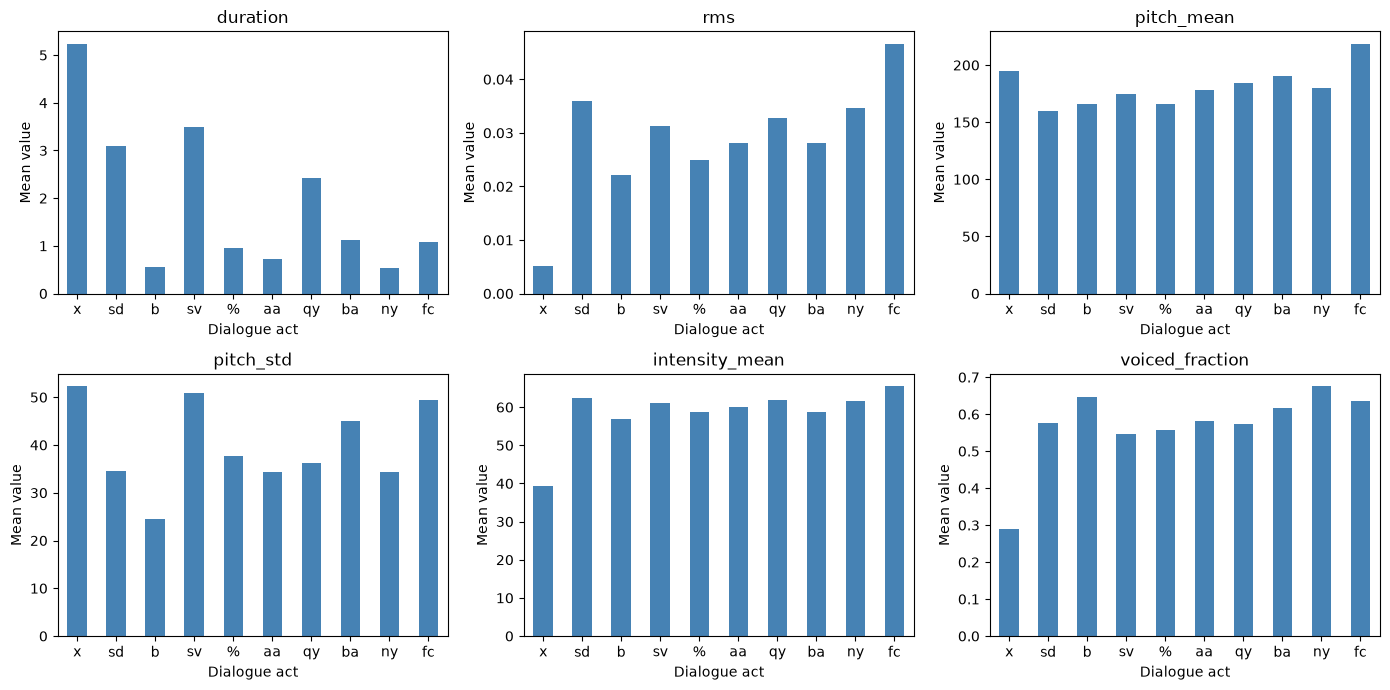

In [76]:
focus = [
    "duration", "rms", "pitch_mean",
    "pitch_std", "intensity_mean", "voiced_fraction"
]

order = train["da_tag"].value_counts().index.tolist()

means = (
    speech_sample.groupby("da_tag")[focus]
    .mean()
    .reindex(order)
)

display(means.round(3))

fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for feature, ax in zip(focus, axes.flat):
    means[feature].plot.bar(ax=ax, rot=0, color="steelblue")
    ax.set_title(feature)
    ax.set_xlabel("Dialogue act")
    ax.set_ylabel("Mean value")

plt.tight_layout()
plt.show()

In [ ]:
def extractPitch(filename, time_step = 0.01, pitch_floor = 75, pitch_ceiling=600):
  pitch = call(filename, "To Pitch", time_step, pitch_floor, pitch_ceiling)

  min_time, max_time, unit, interpolation_method = 0.0, 0.0, "Hertz", "Parabolic"
  pitch_min = call(pitch, "Get minimum", min_time, max_time, unit, interpolation_method)
  pitch_max = call(pitch, "Get maximum", min_time, max_time, unit, interpolation_method)
  pitch_mean = call(pitch, "Get mean", min_time, max_time, unit)
  pitch_std = call(pitch, "Get standard deviation", min_time, max_time, unit)

  return pitch_min, pitch_max, pitch_mean, pitch_std

def extractIntensity(filename, time_step=0.01, pitch_floor=100):
  intensity = call(filename, "To Intensity", pitch_floor, time_step)

  intensity_min = call(intensity, "Get minimum", 0, 0, "Parabolic")
  intensity_max = call(intensity, "Get maximum", 0, 0, "Parabolic")
  intensity_mean = call(intensity, "Get mean", 0, 0)
  intensity_std = call(intensity, "Get standard deviation", 0, 0)

  return intensity_min, intensity_max, intensity_mean, intensity_std

def get_speaking_rate(filename, transcript):
  duration = call(filename, "Get total duration")

  word_count = len(transcript.split())
  speaking_rate = word_count / duration

  return speaking_rate

def extractJitter(filename, pitch_floor = 75, pitch_ceiling=600, period_floor=0.0001, period_ceiling=0.02, maximum_period_factor=1.3):
  min_time, max_time = 0.0, 0.0

  point_process = call(filename, "To PointProcess (periodic, cc)", pitch_floor, pitch_ceiling)
  jitter = call(point_process, "Get jitter (local)",
                min_time, max_time, period_floor, period_ceiling, maximum_period_factor)

  return jitter

def extractShimmer(filename, pitch_floor = 75, pitch_ceiling=600, period_floor=0.0001, period_ceiling=0.02, maximum_period_factor=1.3, maximum_amplitude=1.6):
  min_time, max_time = 0.0, 0.0

  point_process = call(filename, "To PointProcess (periodic, cc)", pitch_floor, pitch_ceiling)
  shimmer = call([filename, point_process], "Get shimmer (local)",
                  min_time, max_time, period_floor,period_ceiling, maximum_period_factor, maximum_amplitude)

  return shimmer

def extractHNR(filename, time_step = 0.01, minimum_pitch = 75, silence_threshold = 0.1, periods = 1.0):
  hnr = call(filename, "To Harmonicity (cc)",
            time_step, minimum_pitch, silence_threshold, periods)
  min_time, max_time = 0.0, 0.0
  hnr_value = call(hnr, "Get mean", min_time, max_time)

  return hnr_value

def audio_process(df, wav_folder):
  rows = []

  for _, row in df.iterrows():
    dialog_id = row['dialog_id']
    speaker = row['speaker']
    da_tag = row.get('da_tag', '')
    start_time = row['start_time']
    end_time = row['end_time']
    transcript = row.get('transcript', '')

    wav_filepath = os.path.join(wav_folder, f"{dialog_id}_{speaker}.wav")
    if not os.path.exists(wav_filepath):
      continue

    try:
        sound = parselmouth.Sound(wav_filepath)

        segment = sound.extract_part(from_time=start_time, to_time=end_time, preserve_times=True)
        
        pitch_min, pitch_max, pitch_mean, pitch_std = extractPitch(segment)
        intensity_min, intensity_max, intensity_mean, intensity_std = extractIntensity(segment)
        speaking_rate = get_speaking_rate(segment, transcript)
        jitter = extractJitter(segment)
        shimmer = extractShimmer(segment)
        hnr = extractHNR(segment)
        
    except Exception as e:
        pitch_min = pitch_max = pitch_mean = pitch_std = None
        intensity_min = intensity_max = intensity_mean = intensity_std = None
        speaking_rate = jitter = shimmer = hnr = None
        
    rows.append({
          "dialog_id": dialog_id,
          "speaker": speaker,
          "da_tag": da_tag,
          "start_time": start_time,
          "end_time": end_time,
          "Min Pitch": pitch_min,
          "Max Pitch": pitch_max,
          "Mean Pitch": pitch_mean,
          "Std Pitch": pitch_std,
          "Min Intensity": intensity_min,
          "Max Intensity": intensity_max,
          "Mean Intensity": intensity_mean,
          "Std Intensity": intensity_std,
          "Speaking Rate": speaking_rate,
          "Jitter": jitter,
          "Shimmer": shimmer,
          "HNR": hnr
    })

  return pd.DataFrame(rows)


In [ ]:
%%capture
train_df_speech = audio_process(train, wav_folder="./wav")
train_df_speech.to_csv("speech_features_train.csv", index=False)

In [ ]:
%%capture
valid_df_speech = audio_process(valid, wav_folder="./wav")
valid_df_speech.to_csv("speech_features_valid.csv", index=False)

In [ ]:
%%capture
test_df_speech = audio_process(test, wav_folder="./wav")
test_df_speech.to_csv("speech_features_test.csv", index=False)

In [94]:
speech_train = pd.read_csv("speech_features_train.csv")
speech_valid = pd.read_csv("speech_features_valid.csv")
speech_test = pd.read_csv("speech_features_test.csv")

speech_train['duration'] = speech_train['end_time'] - speech_train['start_time']
speech_valid['duration'] = speech_valid['end_time'] - speech_valid['start_time']
speech_test['duration'] = speech_test['end_time'] - speech_test['start_time']

availability_cols = [
    "Mean Pitch", "Mean Intensity",
    "Jitter", "Shimmer", "HNR"
]

missing_by_class = (
    speech_train[availability_cols]
    .isna()
    .groupby(speech_train["da_tag"])
    .mean()
    .mul(100)
)

print("Percentage missing within each class:")
display(missing_by_class.round(2))


Percentage missing within each class:


,Mean Pitch,Mean Intensity,Jitter,Shimmer,HNR
da_tag,,,,,
%,1.73,0.02,1.98,2.29,0.07
aa,0.61,0.03,0.70,0.80,0.06
b,1.14,0.03,1.18,1.38,0.03
ba,0.75,0.00,0.75,0.75,0.09
fc,0.78,0.00,0.78,1.10,0.00
ny,0.52,0.00,0.52,0.52,0.00
qy,0.24,0.00,0.24,0.32,0.00
sd,0.26,0.00,0.27,0.29,0.01
sv,0.20,0.00,0.20,0.21,0.00


In [95]:
order = train["da_tag"].value_counts().index.tolist()

meta_cols = ["dialog_id", "speaker", "da_tag", "start_time", "end_time"]
feature_cols = [
    col for col in speech_train.columns
    if col not in meta_cols
]

means = (
    speech_train.groupby("da_tag")[feature_cols]
    .mean()
    .reindex(order)
)

medians = (
    speech_train.groupby("da_tag")[feature_cols]
    .median()
    .reindex(order)
)

print("Class means:")
display(means.round(3))

print("Class medians:")
display(medians.round(3))

Class means:


,Min Pitch,Max Pitch,Mean Pitch,Std Pitch,Min Intensity,Max Intensity,Mean Intensity,Std Intensity,Speaking Rate,Jitter,Shimmer,HNR,duration
da_tag,,,,,,,,,,,,,
x,133.386,329.317,197.314,46.729,-9.154,50.167,25.453,17.044,0.724,0.031,0.141,4.084,4.321
sd,105.498,332.685,166.831,44.548,22.545,70.093,51.940,12.073,3.704,0.020,0.102,10.370,3.137
b,132.180,222.547,169.242,26.748,27.599,62.697,50.895,10.226,2.325,0.020,0.106,10.004,0.630
sv,102.514,351.079,164.811,48.230,20.966,70.897,51.959,12.491,3.679,0.021,0.105,10.171,3.632
%,125.437,259.364,171.523,39.022,25.633,65.779,50.260,11.823,3.280,0.023,0.112,9.002,0.925
aa,129.764,246.251,174.869,34.169,32.119,66.647,53.888,10.229,2.789,0.020,0.100,10.017,0.718
qy,123.104,318.096,180.260,39.150,22.498,71.575,53.887,12.428,4.030,0.018,0.098,11.345,2.255
ba,124.765,287.267,189.810,45.259,24.343,65.967,51.252,11.775,2.823,0.021,0.098,10.035,1.089
ny,141.421,243.315,182.720,32.565,32.570,67.396,54.885,10.604,2.660,0.020,0.105,9.840,0.563


Class medians:


,Min Pitch,Max Pitch,Mean Pitch,Std Pitch,Min Intensity,Max Intensity,Mean Intensity,Std Intensity,Speaking Rate,Jitter,Shimmer,HNR,duration
da_tag,,,,,,,,,,,,,
x,102.680,287.467,179.730,36.292,25.228,50.655,35.271,6.582,0.455,0.023,0.131,3.448,2.197
sd,90.275,287.069,161.495,35.821,28.870,70.835,52.704,10.936,3.568,0.018,0.096,10.441,2.477
b,115.945,207.643,165.989,14.675,33.681,62.909,52.035,7.940,2.155,0.018,0.099,10.079,0.480
sv,88.572,321.426,156.494,40.261,28.319,71.632,52.531,11.288,3.536,0.019,0.100,10.230,2.767
%,107.133,216.896,159.116,20.044,31.840,66.510,51.432,9.841,2.964,0.019,0.104,9.091,0.634
aa,113.278,215.507,169.851,18.240,34.041,67.341,54.966,9.159,2.571,0.017,0.091,10.077,0.565
qy,105.029,279.909,176.339,31.572,29.925,71.987,54.913,10.937,3.885,0.017,0.093,11.318,1.800
ba,105.441,257.318,186.720,36.376,31.454,66.445,52.733,9.499,2.674,0.018,0.090,10.115,0.910
ny,122.912,217.160,170.536,17.846,37.324,68.541,56.430,8.513,2.458,0.017,0.093,9.620,0.445


In [96]:
missing = pd.DataFrame({
    "missing_count": speech_train[feature_cols].isna().sum(),
    "missing_percent": (
        100 * speech_train[feature_cols].isna().mean()
    )
})

display(missing.round(2))

,missing_count,missing_percent
Min Pitch,5297,7.15
Max Pitch,5297,7.15
Mean Pitch,5297,7.15
Std Pitch,5483,7.40
Min Intensity,19,0.03
Max Intensity,19,0.03
Mean Intensity,19,0.03
Std Intensity,26,0.04
Speaking Rate,19,0.03
Jitter,5444,7.35


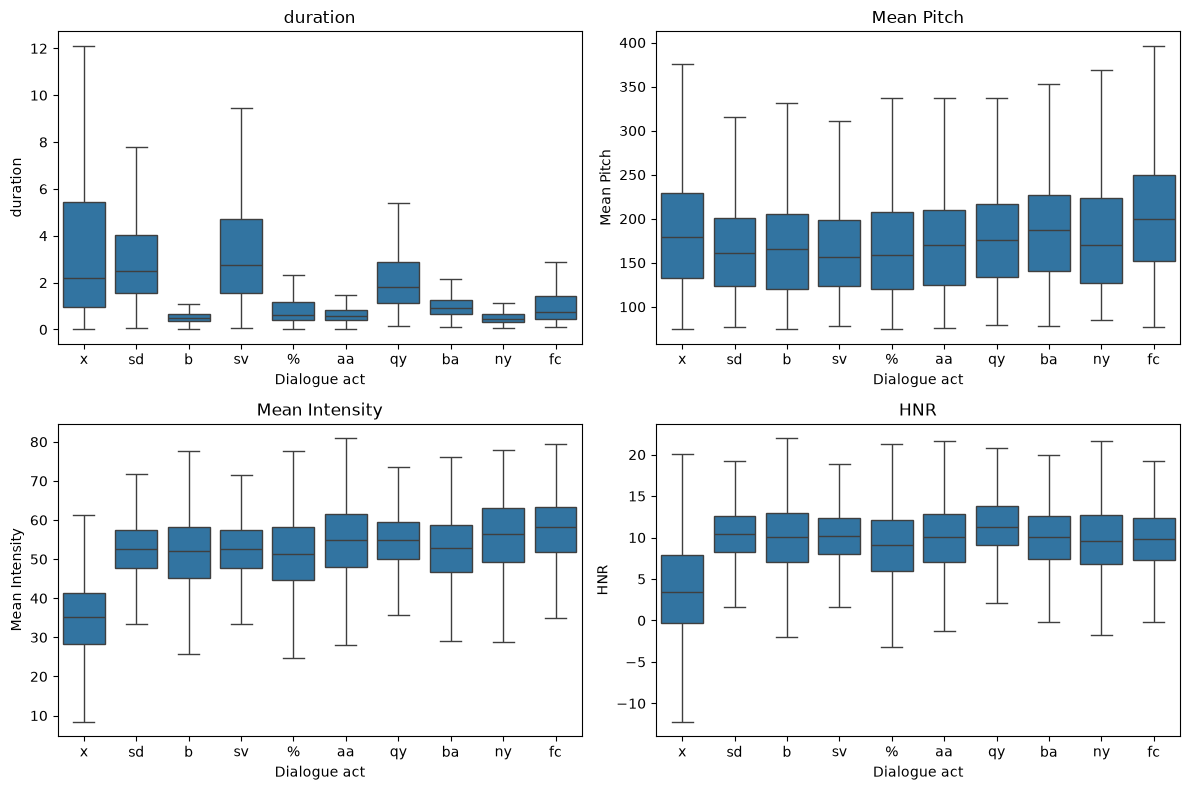

In [98]:
columns = [
    "duration", "Mean Pitch", "Mean Intensity",
     "HNR"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(columns, axes.flat):
    sns.boxplot(
        data=speech_train,
        x="da_tag",
        y=col,
        order=order,
        showfliers=False,
        ax=ax
    )

    ax.set_title(col)
    ax.set_xlabel("Dialogue act")

plt.tight_layout()
plt.show()

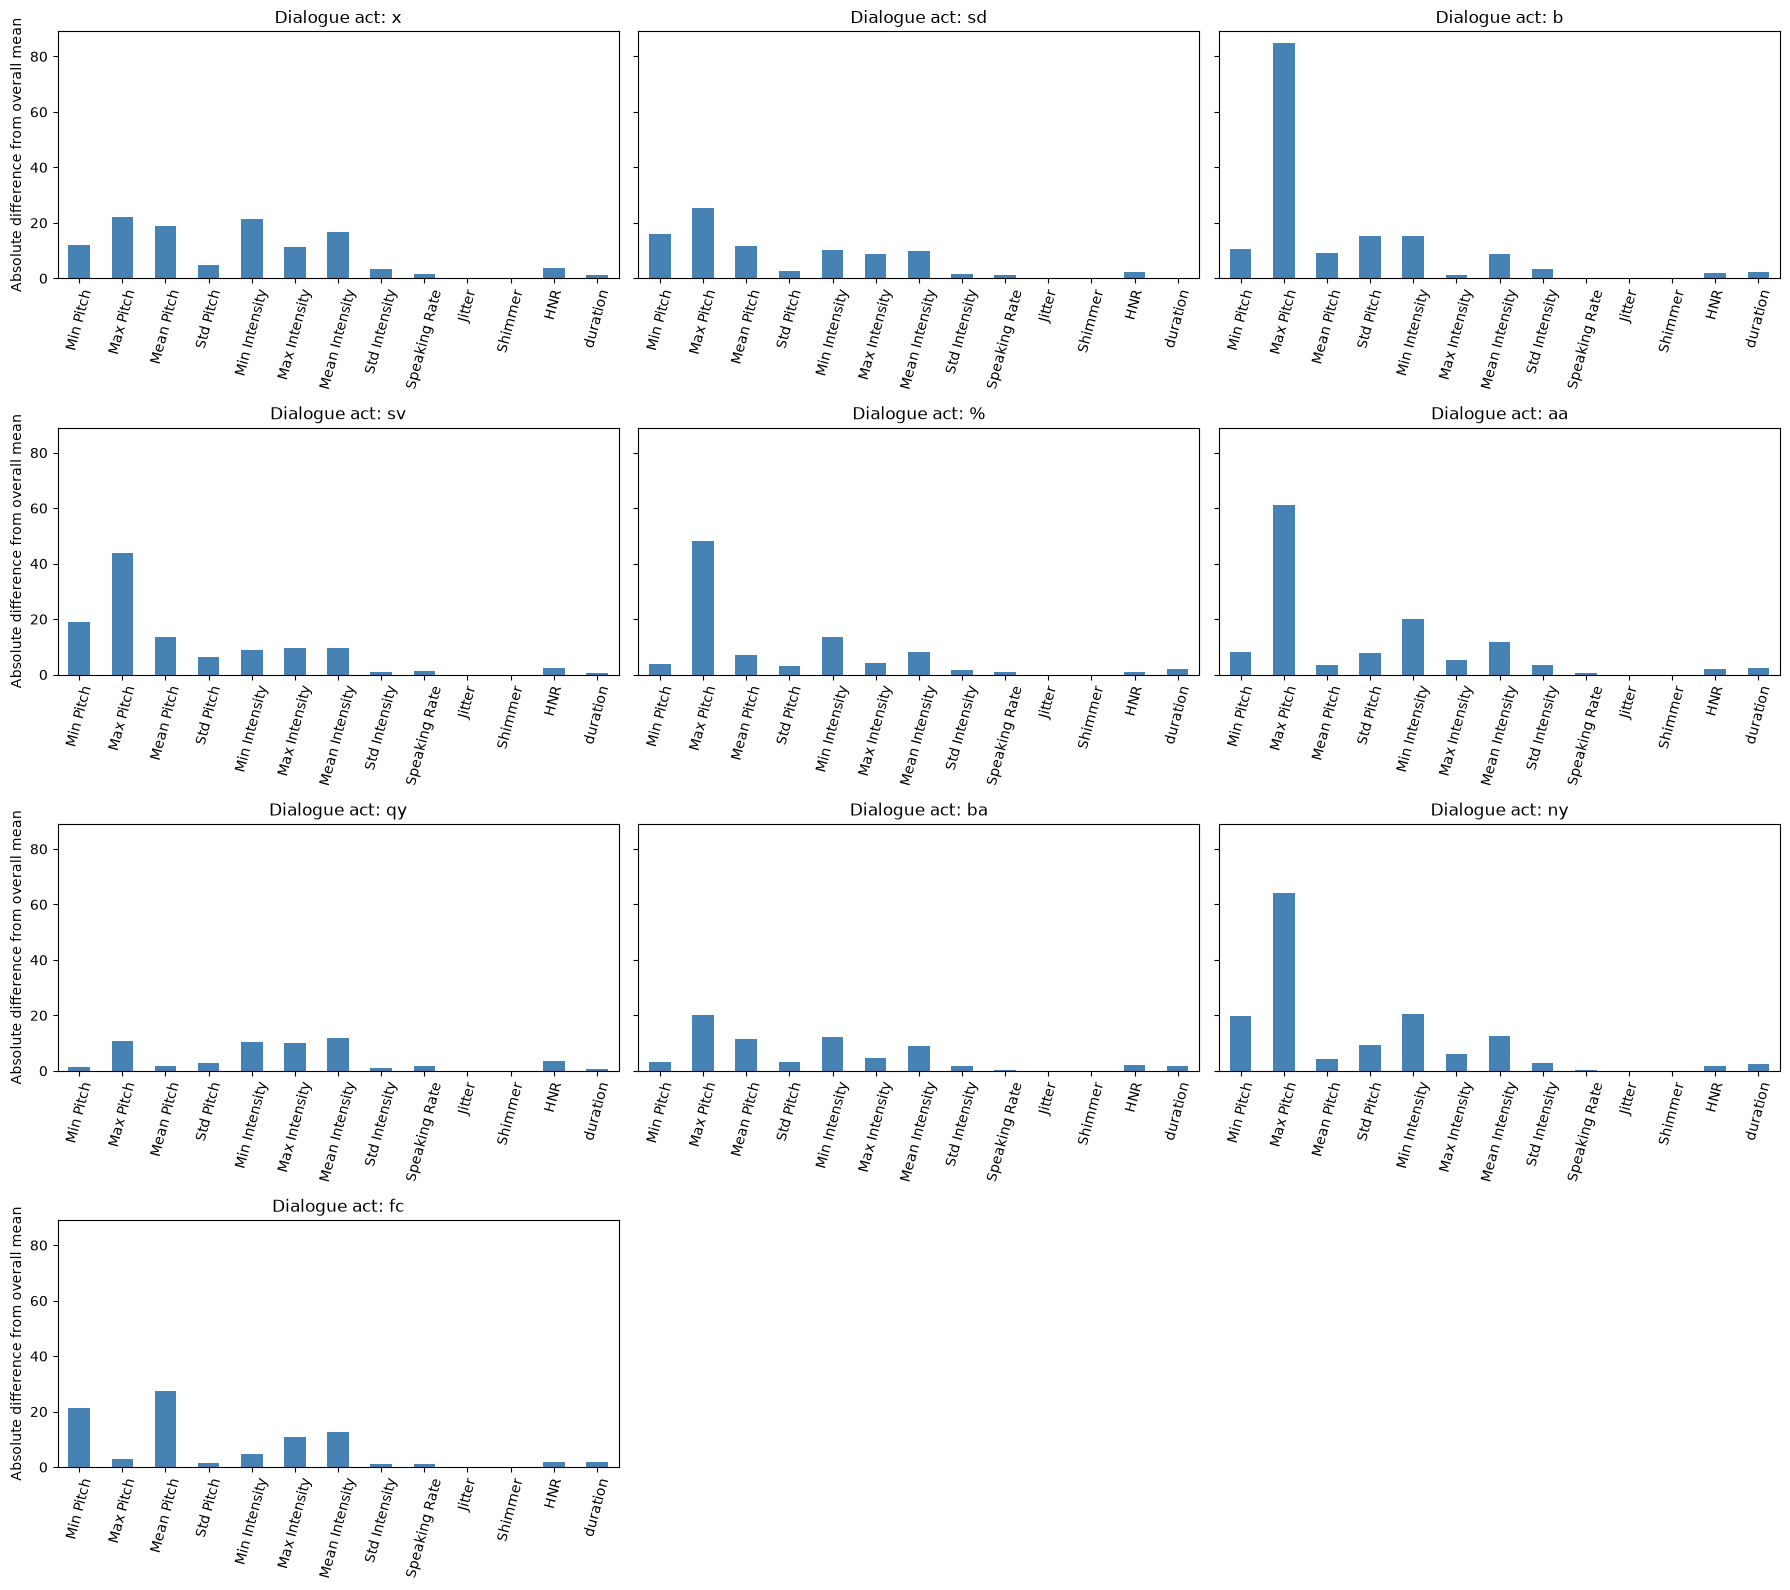

In [100]:
prosodic_features = [
    col for col in speech_train.columns
    if col not in meta_cols
]

overall = speech_train[prosodic_features].mean()
classes = speech_train["da_tag"].value_counts().index

n_cols = 3
n_rows = (len(classes) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, 4 * n_rows),
    sharey=True
)

for label, ax in zip(classes, axes.flat):
    class_mean = speech_train.loc[
        speech_train["da_tag"] == label, prosodic_features
    ].mean()

    differences = (class_mean - overall).abs()

    differences.plot.bar(ax=ax, color="steelblue")
    ax.set_title(f"Dialogue act: {label}")
    ax.set_ylabel("Absolute difference from overall mean")
    ax.tick_params(axis="x", labelrotation=75)

for ax in axes.flat[len(classes):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

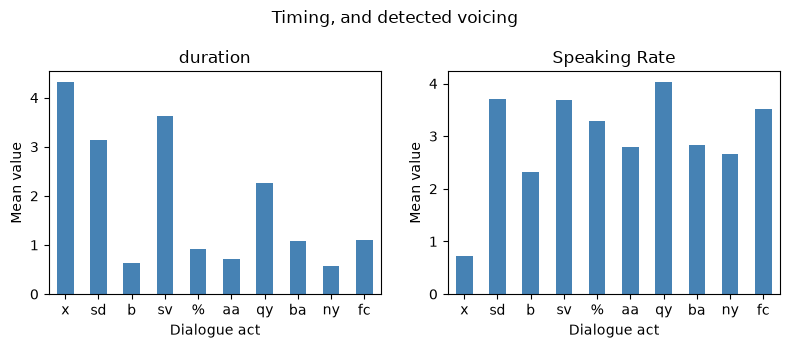

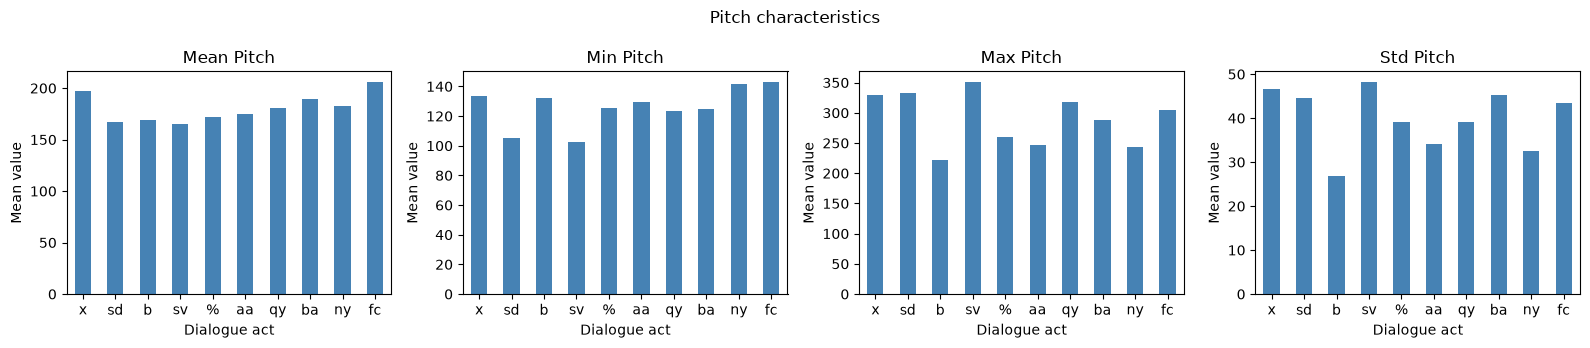

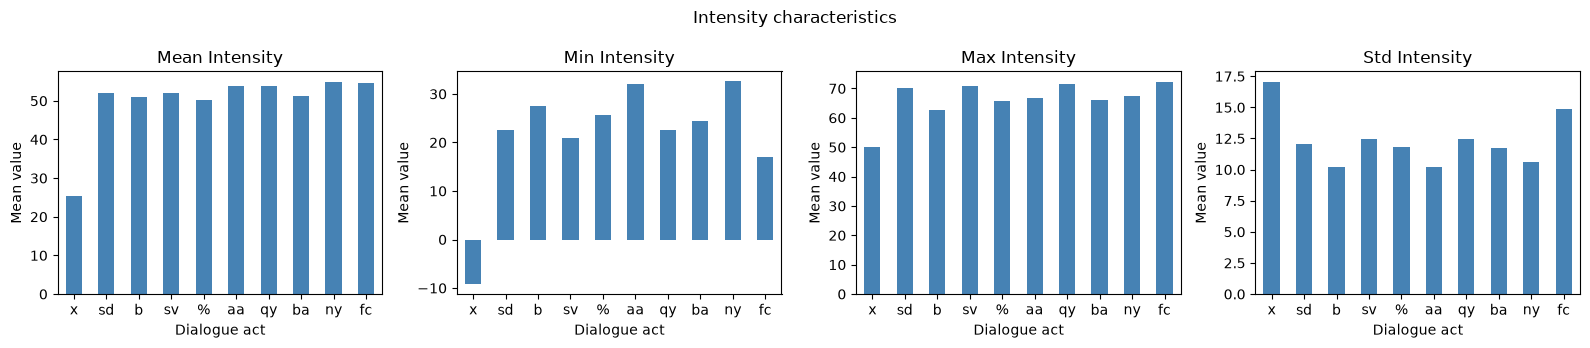

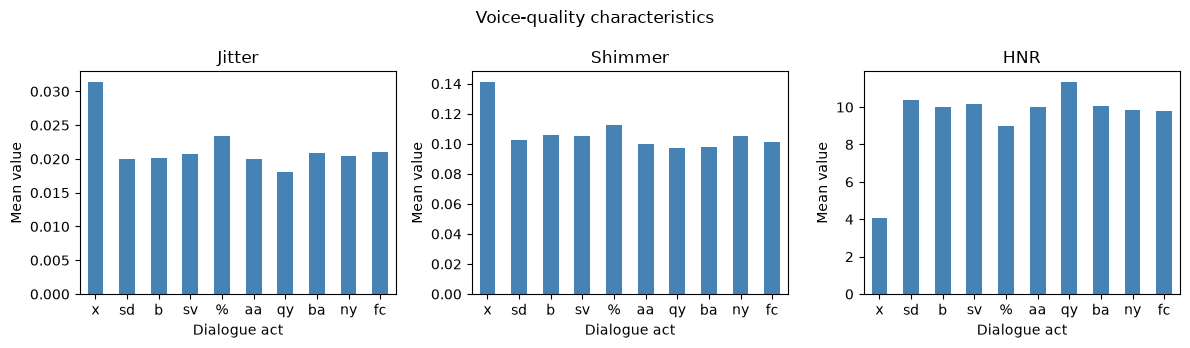

In [101]:
def plot_speech_group(columns, title):
    fig, axes = plt.subplots(
        1, len(columns),
        figsize=(4 * len(columns), 3.5)
    )

    for col, ax in zip(columns, axes):
        means[col].plot.bar(
            ax=ax,
            rot=0,
            color="steelblue"
        )

        ax.set_title(col)
        ax.set_xlabel("Dialogue act")
        ax.set_ylabel("Mean value")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_speech_group(
    ["duration", "Speaking Rate"],
    "Timing, and detected voicing"
)

plot_speech_group(
    ["Mean Pitch","Min Pitch", "Max Pitch", "Std Pitch"],
    "Pitch characteristics"
)

plot_speech_group(
    ["Mean Intensity", "Min Intensity", "Max Intensity", "Std Intensity"],
    "Intensity characteristics"
)

plot_speech_group(
    ["Jitter", "Shimmer", "HNR"],
    "Voice-quality characteristics"
)

In [4]:
import pandas as pd
train = pd.read_csv("task1aa/text_features_train.csv")
valid = pd.read_csv("task1aa/text_features_valid.csv")
test = pd.read_csv("task1aa/text_features_test.csv")

print("Train:", train.shape)
print("Valid:", valid.shape)
print("Test:", test.shape)

speech_train = pd.read_csv("speech_features_train.csv")
speech_valid = pd.read_csv("speech_features_valid.csv")
speech_test = pd.read_csv("speech_features_test.csv")

print("Speech Train:", speech_train.shape)
print("Speech Valid:", speech_valid.shape)      
print("Speech Test:", speech_test.shape)


Train: (74111, 340)
Valid: (19156, 340)
Test: (23540, 340)
Speech Train: (74111, 17)
Speech Valid: (19156, 17)
Speech Test: (23540, 17)


## Hypothesis testing / Feature Analysis

In [10]:
from scipy.stats import mannwhitneyu, chi2_contingency, kruskal
from statsmodels.stats.multitest import multipletests

data = train.copy()

tests = []

def check_numeric(name, feature, group_a, group_b, label_a, label_b):
    a = data.loc[group_a, feature].dropna()
    b = data.loc[group_b, feature].dropna()

    stat, p = mannwhitneyu(a, b, alternative="two-sided")

    # Positive values mean group A tends to have higher values.
    effect = 2 * stat / (len(a) * len(b)) - 1

    tests.append({
        "Hypothesis": name,
        "Feature": feature,
        "Group A": label_a,
        "Group B": label_b,
        "A mean / %": a.mean(),
        "B mean / %": b.mean(),
        "A median": a.median(),
        "B median": b.median(),
        "Effect": effect,
        "Effect measure": "Rank-biserial",
        "p": p
    })


def check_binary(name, values, group_a, group_b, label_a, label_b):
    a = values.loc[group_a].astype(int)
    b = values.loc[group_b].astype(int)

    table = [
        [a.sum(), len(a) - a.sum()],
        [b.sum(), len(b) - b.sum()]
    ]

    stat, p, _, _ = chi2_contingency(table, correction=False)

    tests.append({
        "Hypothesis": name,
        "Feature": values.name,
        "Group A": label_a,
        "Group B": label_b,
        "A mean / %": a.mean() * 100,
        "B mean / %": b.mean() * 100,
        "A median": np.nan,
        "B median": np.nan,
        "Effect": (a.mean() - b.mean()) * 100,
        "Effect measure": "Percentage-point difference",
        "p": p
    })


statements = data["da_tag"].isin(["sd", "sv"])
responses = data["da_tag"].isin(["b", "aa", "ny"])

check_numeric(
    "Statements are longer",
    "word_count",
    statements, responses,
    "sd / sv", "b / aa / ny"
)

check_binary(
    "Repetition is more frequent in sv than sd",
    (data["repeat_count"] > 0).rename("has_repeat"),
    data["da_tag"].eq("sv"),
    data["da_tag"].eq("sd"),
    "sv", "sd"
)

check_numeric(
    "Responses have higher assent scores",
    "liwc_assent",
    responses, statements,
    "b / aa / ny", "sd / sv"
)

check_numeric(
    "Appreciations have higher positive-emotion scores",
    "liwc_posemo",
    data["da_tag"].eq("ba"), statements,
    "ba", "sd / sv"
)

check_binary(
    "Opening oh is associated with ba",
    data["first_oh"],
    data["da_tag"].eq("ba"),
    ~data["da_tag"].isin(["ba", "x"]),
    "ba", "Other spoken classes"
)

summary = pd.DataFrame(tests)

# Adjust for testing several hypotheses.
summary["Adjusted p"] = multipletests(
    summary["p"], method="holm"
)[1]

display(
    summary.drop(columns="p").round(4)
)

,Hypothesis,Feature,Group A,Group B,A mean / %,B mean / %,A median,B median,Effect,Effect measure,Adjusted p
0,Statements are longer,word_count,sd / sv,b / aa / ny,10.8833,1.2227,9.00,1.0,0.9645,Rank-biserial,0.0
1,Repetition is more frequent in sv than sd,has_repeat,sv,sd,18.2244,14.5804,NaN,NaN,3.6440,Percentage-point difference,0.0
2,Responses have higher assent scores,liwc_assent,b / aa / ny,sd / sv,0.7096,0.0017,1.00,0.0,0.7357,Rank-biserial,0.0
3,Appreciations have higher positive-emotion scores,liwc_posemo,ba,sd / sv,0.3160,0.0560,0.25,0.0,0.4061,Rank-biserial,0.0
4,Opening oh is associated with ba,first_oh,ba,Other spoken classes,35.9360,2.7507,NaN,NaN,33.1853,Percentage-point difference,0.0


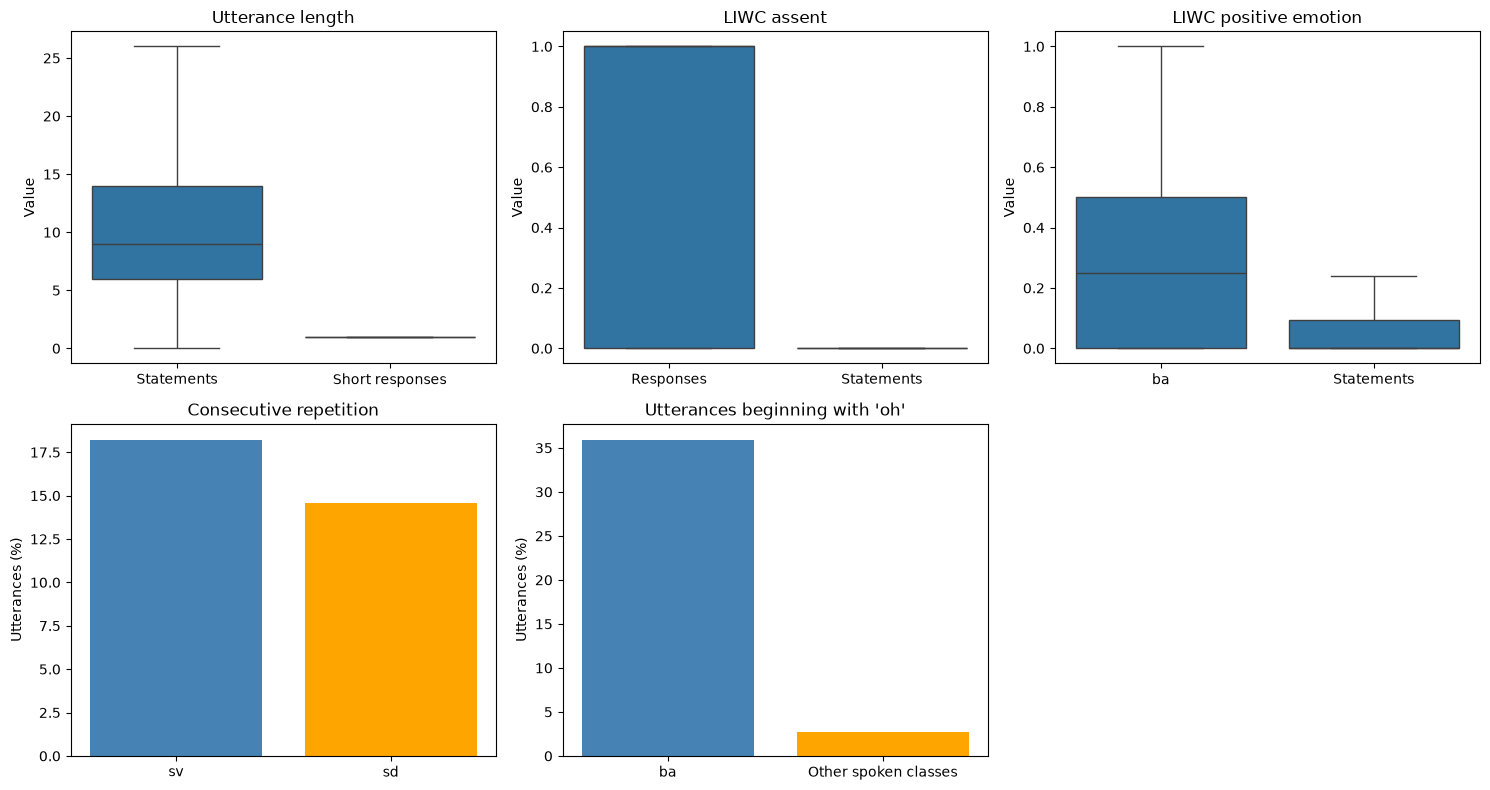

In [13]:
import seaborn as sns
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

plots = [
    ("word_count", statements, responses,
     "Statements", "Short responses", "Utterance length"),

    ("liwc_assent", responses, statements,
     "Responses", "Statements", "LIWC assent"),

    ("liwc_posemo", data["da_tag"].eq("ba"), statements,
     "ba", "Statements", "LIWC positive emotion")
]

for ax, (feature, mask_a, mask_b, name_a, name_b, title) in zip(
    axes[0], plots
):
    values = pd.DataFrame({
        "Value": pd.concat([
            data.loc[mask_a, feature],
            data.loc[mask_b, feature]
        ], ignore_index=True),
        "Group": (
            [name_a] * mask_a.sum()
            + [name_b] * mask_b.sum()
        )
    })

    sns.boxplot(
        data=values, x="Group", y="Value",
        showfliers=False, ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("")

binary_plots = [
    (
        data["repeat_count"].gt(0),
        data["da_tag"].eq("sv"),
        data["da_tag"].eq("sd"),
        ["sv", "sd"],
        "Consecutive repetition"
    ),
    (
        data["first_oh"],
        data["da_tag"].eq("ba"),
        ~data["da_tag"].isin(["ba", "x"]),
        ["ba", "Other spoken classes"],
        "Utterances beginning with 'oh'"
    )
]

for ax, (values, mask_a, mask_b, names, title) in zip(
    axes[1], binary_plots
):
    percentages = [
        values.loc[mask_a].mean() * 100,
        values.loc[mask_b].mean() * 100
    ]

    ax.bar(names, percentages, color=["steelblue", "orange"])
    ax.set_title(title)
    ax.set_ylabel("Utterances (%)")

axes[1, 2].axis("off")

plt.tight_layout()
plt.show()

,Feature,H statistic,Effect estimate,Adjusted p
6,pos_pron,48615.1675,0.6559,0.0
7,pos_intj,44739.7679,0.6036,0.0
0,pos_noun,39671.5653,0.5353,0.0
3,pos_aux,38847.3002,0.5241,0.0
2,pos_verb,38038.3886,0.5132,0.0
5,pos_adv,24142.2834,0.3257,0.0
4,pos_adj,20690.0160,0.2791,0.0
1,pos_propn,3728.0155,0.0502,0.0


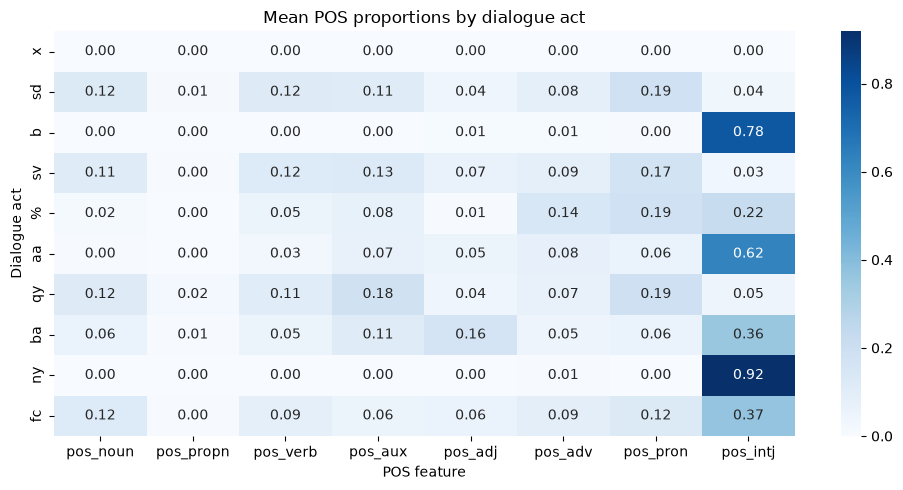

In [14]:
pos_cols = [col for col in data.columns if col.startswith("pos_")]
labels = data["da_tag"].value_counts().index

pos_results = []

for feature in pos_cols:
    groups = [
        data.loc[data["da_tag"].eq(label), feature].dropna()
        for label in labels
    ]

    h, p = kruskal(*groups)

    n = sum(len(group) for group in groups)
    k = len(groups)

    effect = max(0, (h - k + 1) / (n - k))

    pos_results.append({
        "Feature": feature,
        "H statistic": h,
        "Effect estimate": effect,
        "p": p
    })

pos_results = pd.DataFrame(pos_results)

pos_results["Adjusted p"] = multipletests(
    pos_results["p"], method="holm"
)[1]

display(
    pos_results.drop(columns="p")
    .sort_values("Effect estimate", ascending=False)
    .round(4)
)

pos_means = data.groupby("da_tag")[pos_cols].mean().reindex(labels)

plt.figure(figsize=(10, 5))
sns.heatmap(pos_means, annot=True, fmt=".2f", cmap="Blues")
plt.title("Mean POS proportions by dialogue act")
plt.xlabel("POS feature")
plt.ylabel("Dialogue act")
plt.tight_layout()
plt.show()